# Frozen cross-type evaluation and local-audit artifacts

Reused simulated benchmark, not external field validation. Repeated fits do not add independent benign edits.

In [1]:
from pathlib import Path
import sys, json
from IPython.display import display, Markdown, Image
import pandas as pd
ROOT=Path.cwd()
if not (ROOT/'src').is_dir(): ROOT=ROOT.parent
sys.path.insert(0,str(ROOT/'src'))
sys.path.insert(0,str(ROOT/'tools'))


In [2]:
from engine import evaluate_test
evaluate_test(ROOT,16)

FROZEN_TEST_SCORING 980 models 1440 cases


TEST_COMPLETE 8640 setting rows


In [3]:
from report import figures
figures(ROOT)
display(pd.read_csv(ROOT/'results/model_budget_summary.csv').head(30))
display(Markdown((ROOT/'reports/complete_results.md').read_text()))

FIGURE_GROUPS 8


,train_type,budget,method,known_change_f1_mean,known_change_f1_std,known_change_f1_min,known_recall_mean,known_recall_std,known_recall_min,known_change_ba_mean,...,normal_fpr_min,activation_fpr_mean,activation_fpr_std,activation_fpr_min,training_seconds_mean,training_seconds_std,training_seconds_min,event_latency_ms_mean,event_latency_ms_std,event_latency_ms_min
0,Mechanism-1,10,DeepSAD,0.446325,0.252927,0.110455,0.496889,0.340498,0.050940,0.737333,...,0.000000,0.000000,0.000000,0.000000,0.148523,0.001685,0.146656,0.136998,0.002185,0.134361
1,Mechanism-1,10,RF,0.864626,0.050466,0.794545,0.935577,0.054563,0.846154,0.923344,...,0.000000,0.000000,0.000000,0.000000,0.095286,0.002469,0.093234,2.608216,0.056268,2.549722
2,Mechanism-1,10,SDTN,0.769131,0.045953,0.717542,0.875756,0.043083,0.814877,0.926767,...,0.000000,0.027984,0.028122,0.000000,0.240727,0.000884,0.239348,0.275002,0.006123,0.270532
3,Mechanism-1,10,SS,0.546438,0.162594,0.365935,0.639639,0.212540,0.390233,0.819820,...,0.000000,0.009877,0.022085,0.000000,0.743660,0.016571,0.729370,0.272952,0.002494,0.268583
4,Mechanism-1,10,U,0.367405,0.037970,0.302417,0.402118,0.064881,0.289542,0.678837,...,0.031746,0.048560,0.008922,0.032922,12.747047,0.003532,12.742506,0.374296,0.005050,0.369983
5,Mechanism-1,10,U+RF,0.864626,0.050466,0.794545,0.935577,0.054563,0.846154,0.923344,...,0.000000,0.000000,0.000000,0.000000,12.842333,0.003833,12.835740,2.982512,0.054987,2.921691
6,Mechanism-1,10,U+SDTN,0.765921,0.032796,0.717542,0.878414,0.046232,0.814877,0.928096,...,0.011905,0.025514,0.017067,0.012346,12.987774,0.003687,12.983017,0.649298,0.007571,0.642501
7,Mechanism-1,2,DeepSAD,0.405150,0.232406,0.129788,0.451016,0.323869,0.070981,0.725508,...,0.000000,0.000000,0.000000,0.000000,0.209106,0.063958,0.137765,0.134321,0.004069,0.128941
8,Mechanism-1,2,RF,0.606245,0.064171,0.535860,0.724633,0.079614,0.638559,0.840094,...,0.000000,0.000000,0.000000,0.000000,0.091552,0.001049,0.089816,2.503625,0.027605,2.463621
9,Mechanism-1,2,SDTN,0.585862,0.082680,0.459276,0.709421,0.107565,0.537003,0.854710,...,0.019841,0.039506,0.014136,0.020576,14.462969,0.004496,14.455488,0.275888,0.010791,0.269057


# Six-mechanism few-attack-label EV-CMA results

Catt=0.15; fixed source holdout; simulated and previously studied benchmark.
Each mechanism jointly trains Type-i and Type-i-ta. The primary F1 equally averages the two variants' change-only binary class-macro F1s.
N+20 attack labels are used per task. Every method uses the same subsets and normal-validation constraints.

N is the combined attack count over both variants. Finite budgets are balanced within one record; All covers all distinct eligible sources and may be imbalanced.
## Results by training-label budget (equal weight over six training mechanisms)

### N=2

|Method|Known-mechanism change F1|Known recall|Other-five-mechanism recall|Mean edit FP / 9|
|---|---:|---:|---:|---:|
|U|0.6056|0.6627|0.6627|0.40|
|RF|0.7699|0.8340|0.5500|0.50|
|SDTN|0.7264|0.7782|0.3128|0.00|
|DeepSAD|0.6950|0.7076|0.5381|0.00|
|SS|0.5414|0.6051|0.3228|0.10|
|U+RF|0.7713|0.8344|0.5518|0.50|
|U+SDTN|0.7852|0.8397|0.6892|0.30|

### N=5

|Method|Known-mechanism change F1|Known recall|Other-five-mechanism recall|Mean edit FP / 9|
|---|---:|---:|---:|---:|
|U|0.6056|0.6627|0.6627|0.40|
|RF|0.8398|0.8926|0.5273|0.43|
|SDTN|0.7897|0.8496|0.3904|0.07|
|DeepSAD|0.6849|0.7010|0.5352|0.03|
|SS|0.6505|0.7231|0.4076|0.03|
|U+RF|0.8398|0.8926|0.5273|0.43|
|U+SDTN|0.8308|0.8854|0.6993|0.37|

### N=10

|Method|Known-mechanism change F1|Known recall|Other-five-mechanism recall|Mean edit FP / 9|
|---|---:|---:|---:|---:|
|U|0.6056|0.6627|0.6627|0.40|
|RF|0.8887|0.9470|0.4772|0.40|
|SDTN|0.8414|0.9040|0.3170|0.20|
|DeepSAD|0.6966|0.7184|0.5352|0.03|
|SS|0.6710|0.7389|0.4087|0.03|
|U+RF|0.8887|0.9470|0.4774|0.40|
|U+SDTN|0.8731|0.9304|0.7043|0.57|

### N=20

|Method|Known-mechanism change F1|Known recall|Other-five-mechanism recall|Mean edit FP / 9|
|---|---:|---:|---:|---:|
|U|0.6056|0.6627|0.6627|0.40|
|RF|0.9319|0.9774|0.5252|0.43|
|SDTN|0.8595|0.9026|0.3265|0.17|
|DeepSAD|0.6997|0.7211|0.5380|0.00|
|SS|0.7359|0.7903|0.4509|0.10|
|U+RF|0.9319|0.9774|0.5255|0.43|
|U+SDTN|0.8783|0.9180|0.6909|0.37|

### N=50

|Method|Known-mechanism change F1|Known recall|Other-five-mechanism recall|Mean edit FP / 9|
|---|---:|---:|---:|---:|
|U|0.6056|0.6627|0.6627|0.40|
|RF|0.9441|0.9799|0.4659|0.33|
|SDTN|0.9198|0.9512|0.3109|0.13|
|DeepSAD|0.7084|0.7276|0.5374|0.00|
|SS|0.7875|0.8364|0.4742|0.03|
|U+RF|0.9441|0.9799|0.4671|0.33|
|U+SDTN|0.9028|0.9348|0.6955|0.37|

### N=All

|Method|Known-mechanism change F1|Known recall|Other-five-mechanism recall|Mean edit FP / 9|
|---|---:|---:|---:|---:|
|U|0.6056|0.6627|0.6627|0.40|
|RF|0.9863|0.9989|0.5363|0.33|
|SDTN|0.9397|0.9594|0.3413|0.23|
|DeepSAD|0.7149|0.7371|0.5363|0.00|
|SS|0.8084|0.8481|0.5078|0.03|
|U+RF|0.9863|0.9989|0.5364|0.33|
|U+SDTN|0.9148|0.9374|0.7137|0.33|

## Interpretation limits

- Nine test edits are nine observations, not 45 observations after five repeats. Report exact per-repeat errors.
- Other settings were withheld from the current training and selection. Architectures and this benchmark were studied previously; this is not proof of genuinely unforeseen attacks.
- Normal validation constraints are empirical and do not guarantee population or test acceptance.
- Preset U uses no current attack labels for fitting or selection; its historical architecture is not evidence of zero historical research-label cost.
- Original generator fingerprints remain unchanged. Start-time manipulation is an easy cue in these data; feature-group results are diagnostic.
- Source bootstrap is conditional on fitted models. Attack-burst dependence is not fully resolved by source grouping, and intervals are not multiplicity adjusted.
- Parallel methods include both component inference costs. Training times include cached-work timing and are not a clean hardware-normalized benchmark.
- The two class F1s use the observed, attack-heavy test mix. Balanced accuracy and edit FP are essential companions.


### benign_update_and_cost_n20

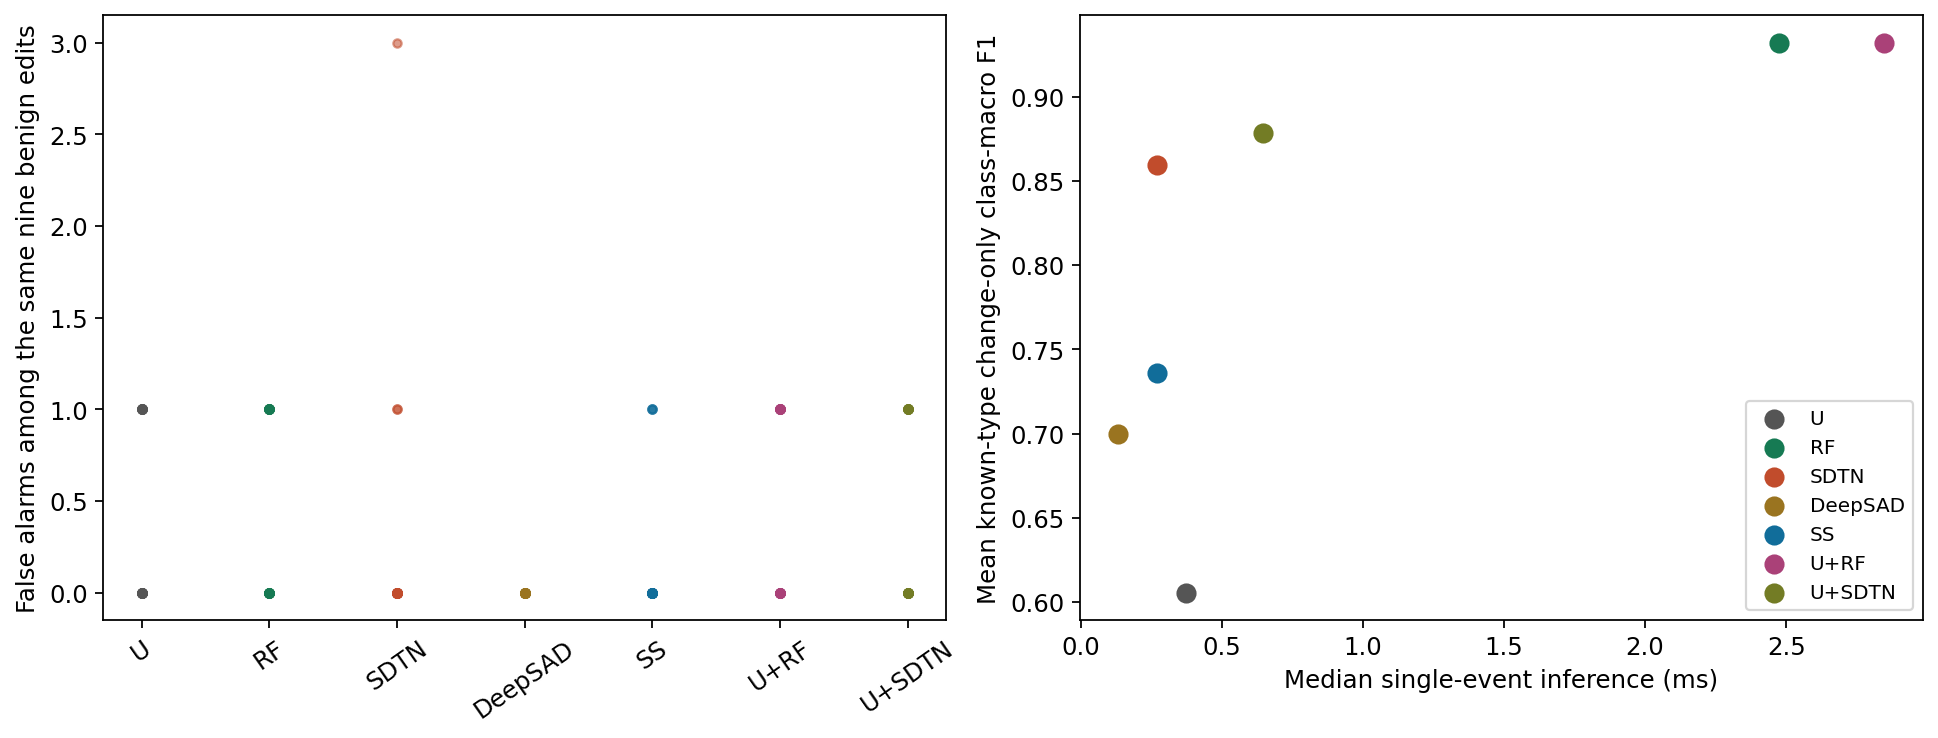

### cross_type_learning_curves

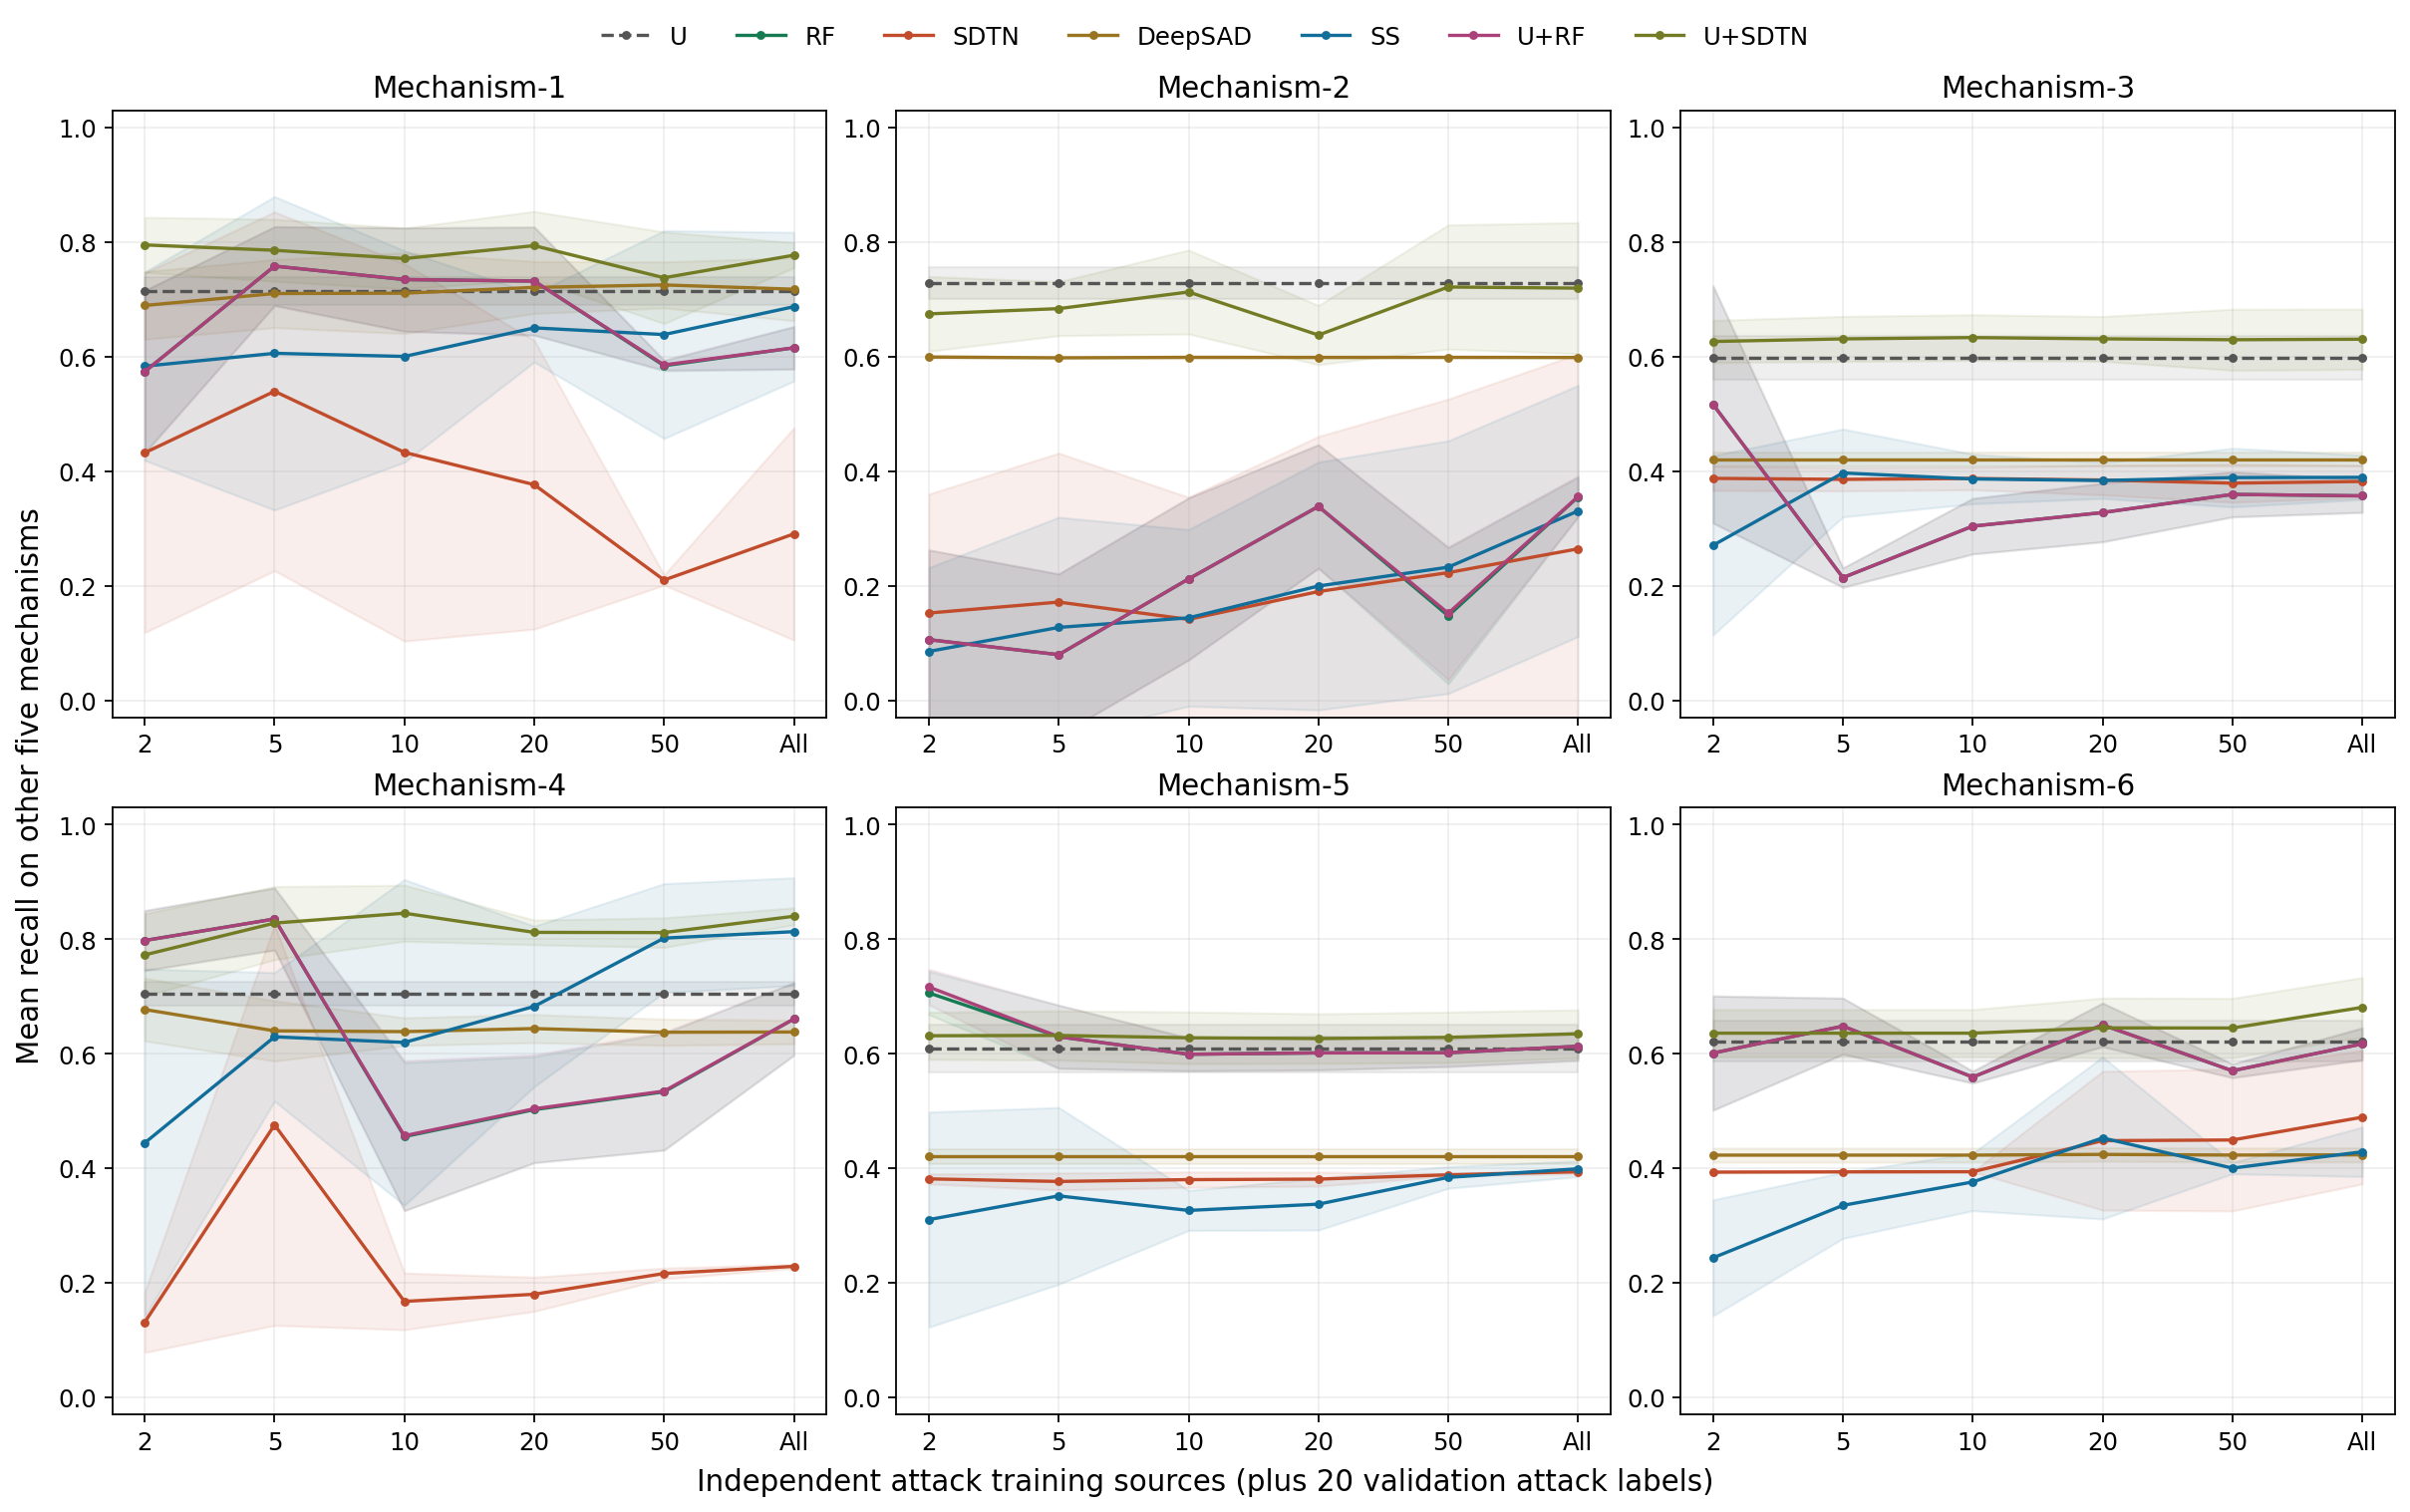

### cross_type_recall_n20

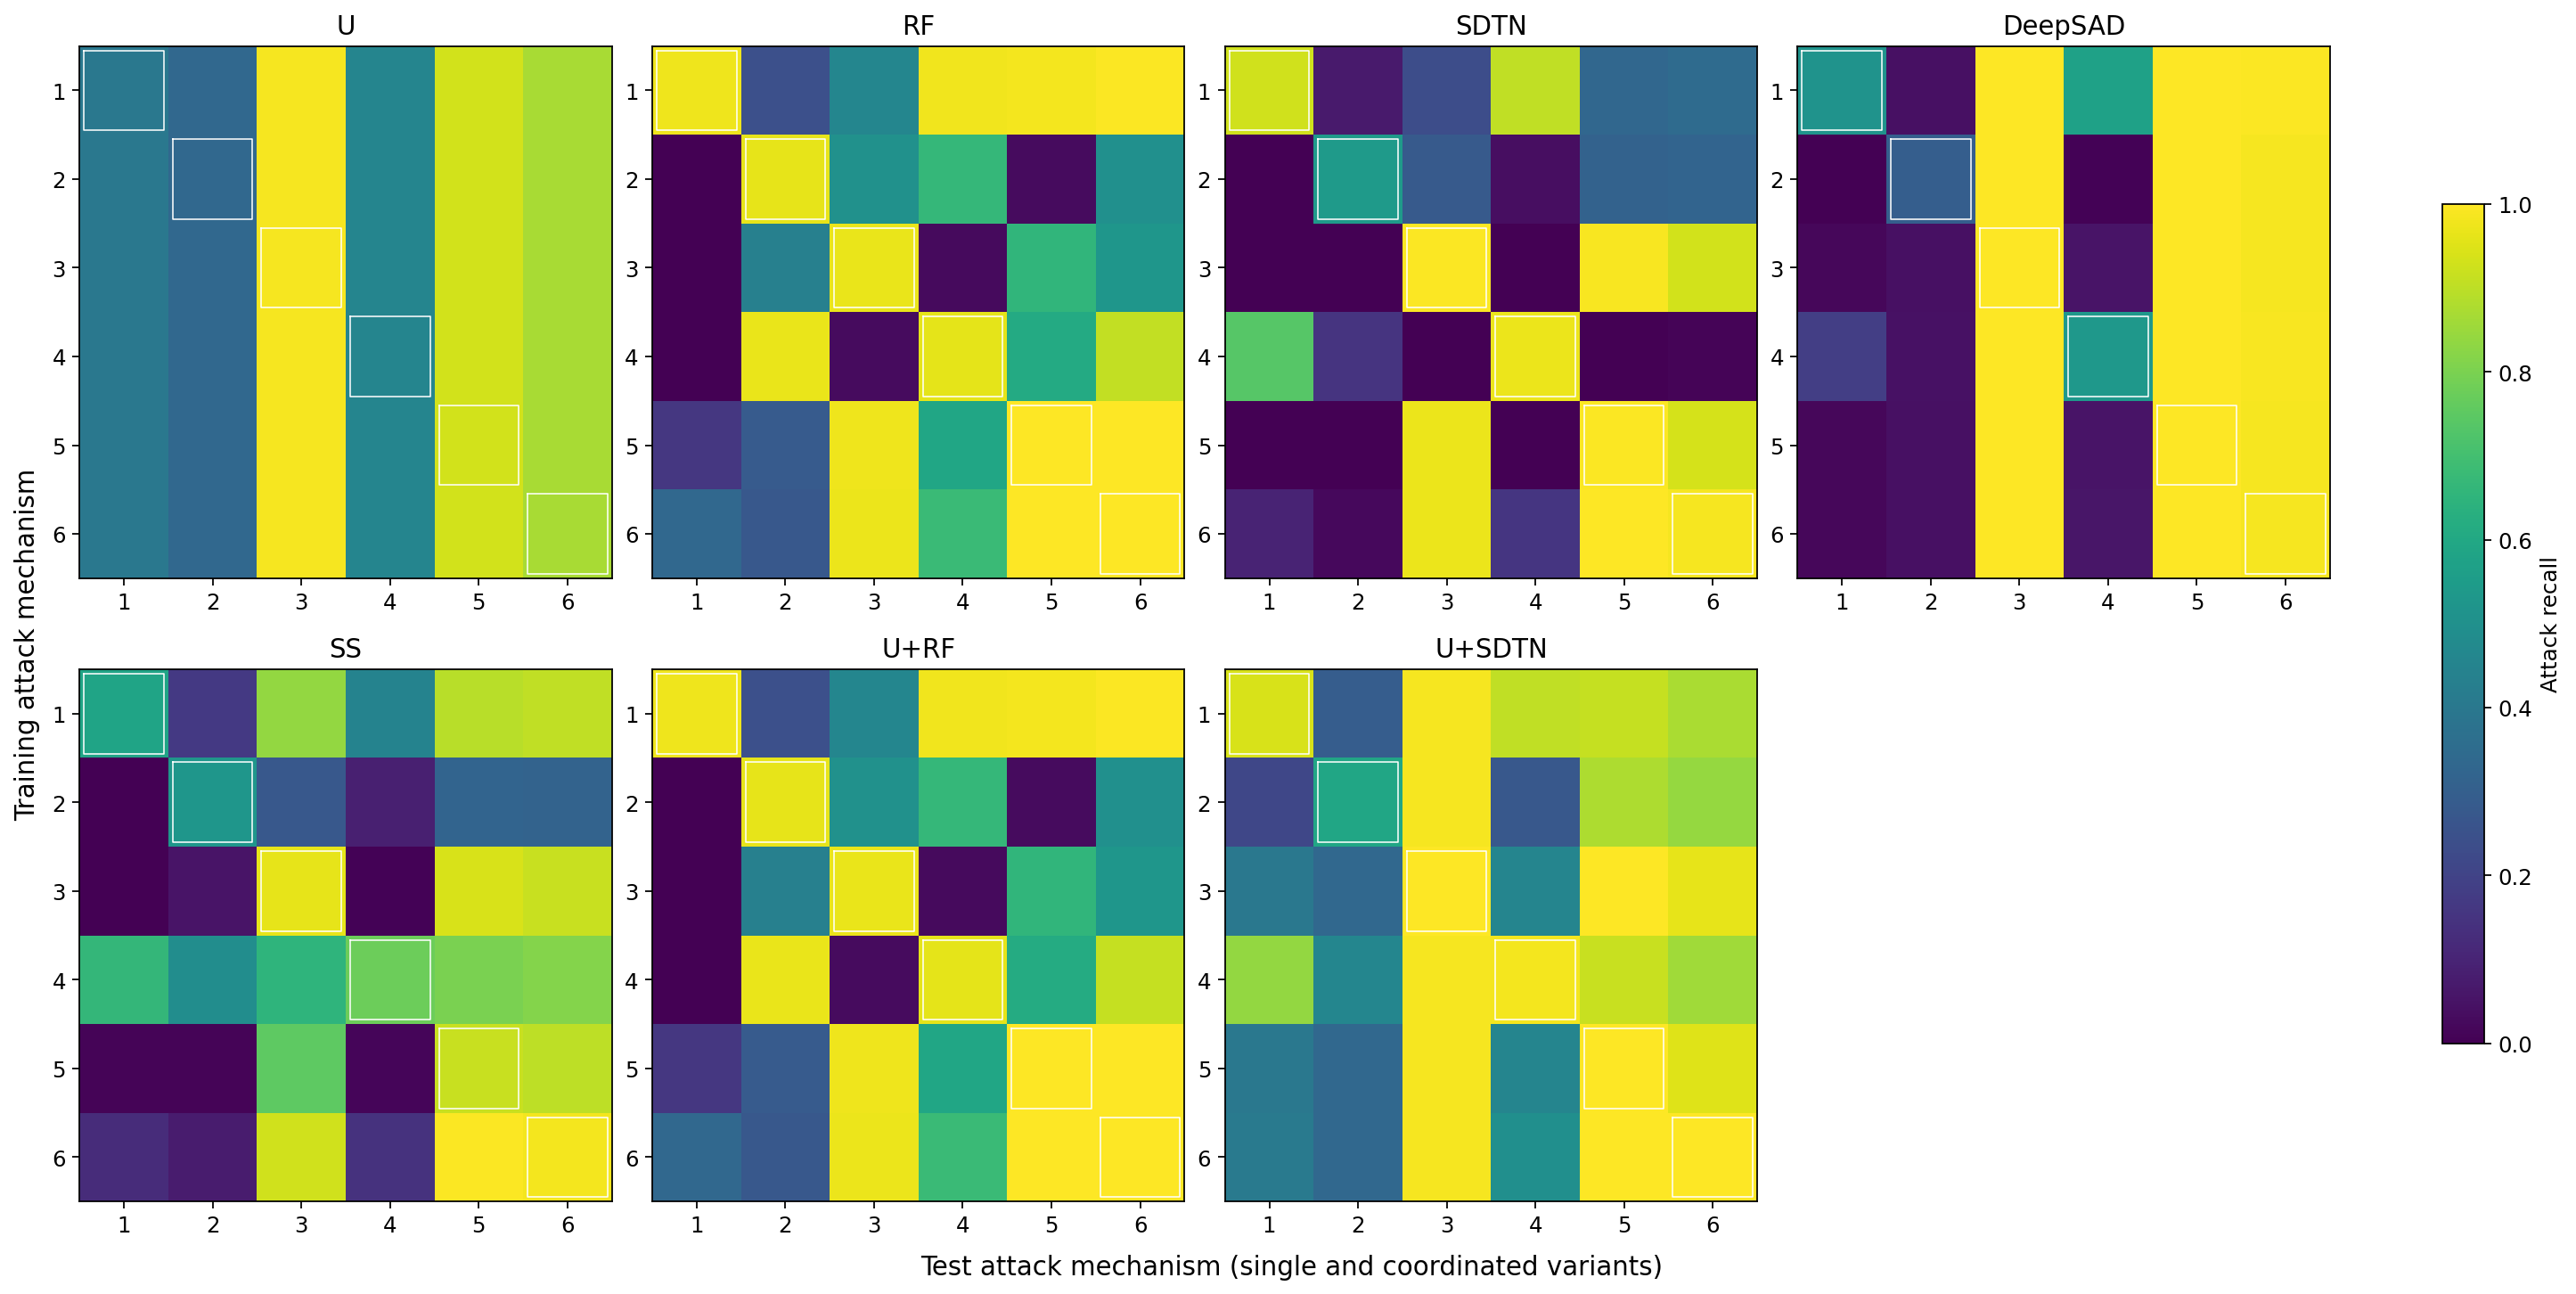

### cross_type_recall_n5

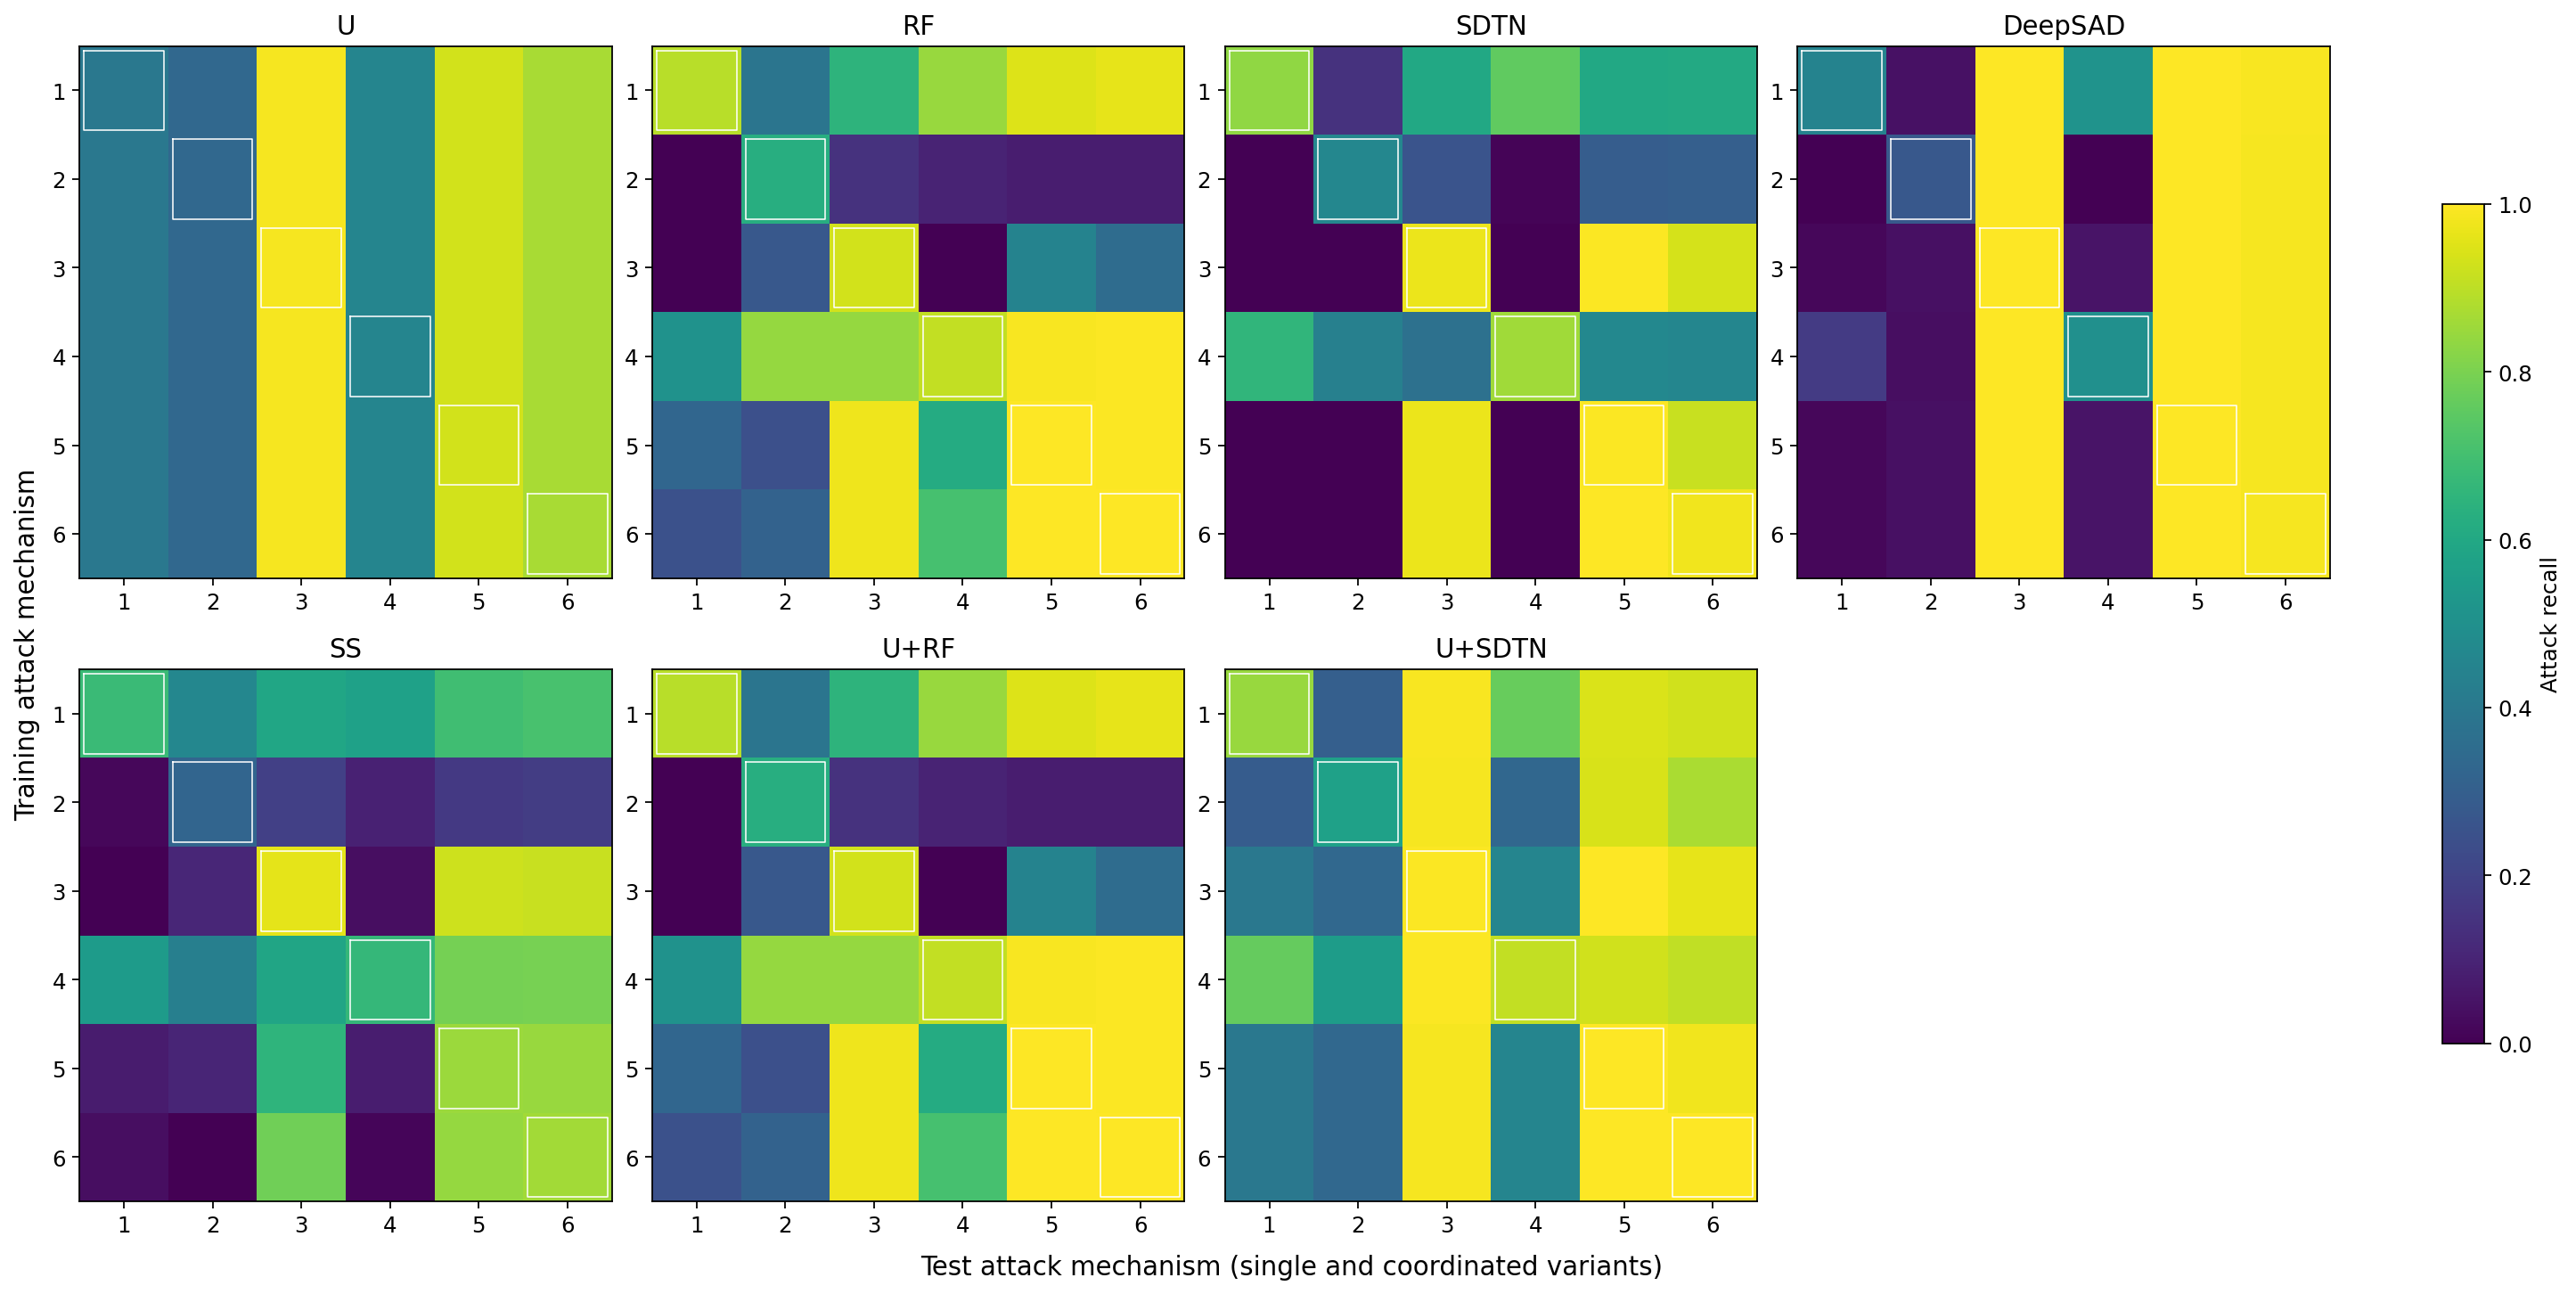

### cross_type_recall_nAll

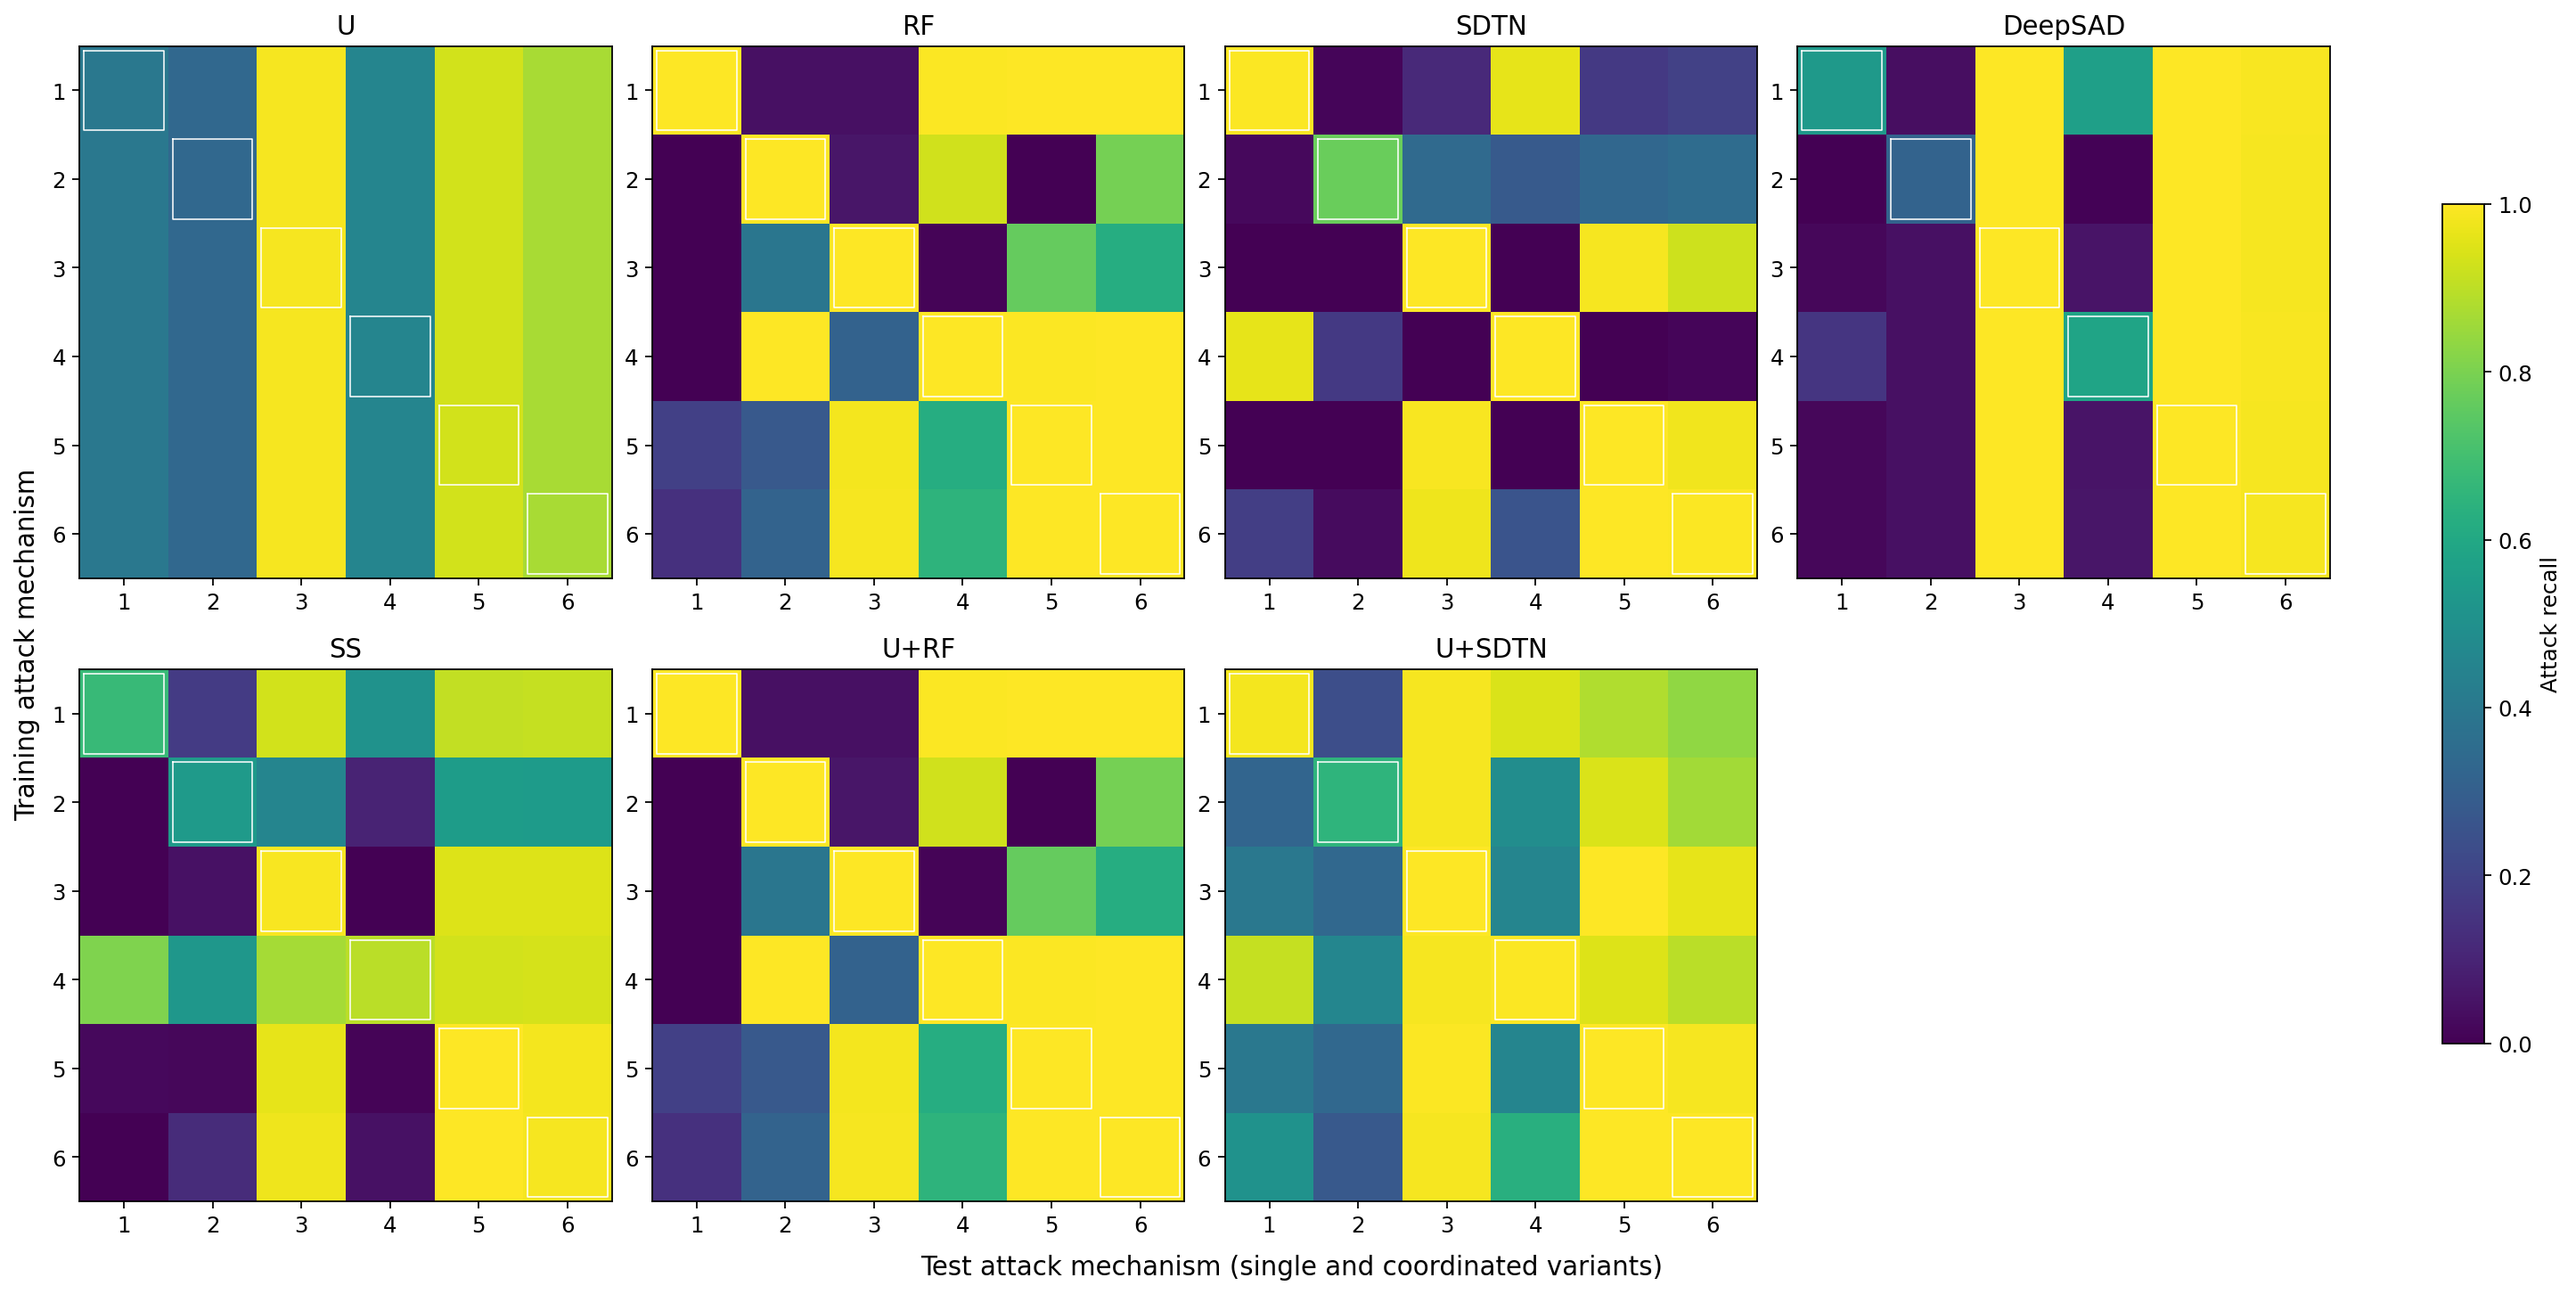

### generator_feature_diagnostic_n20

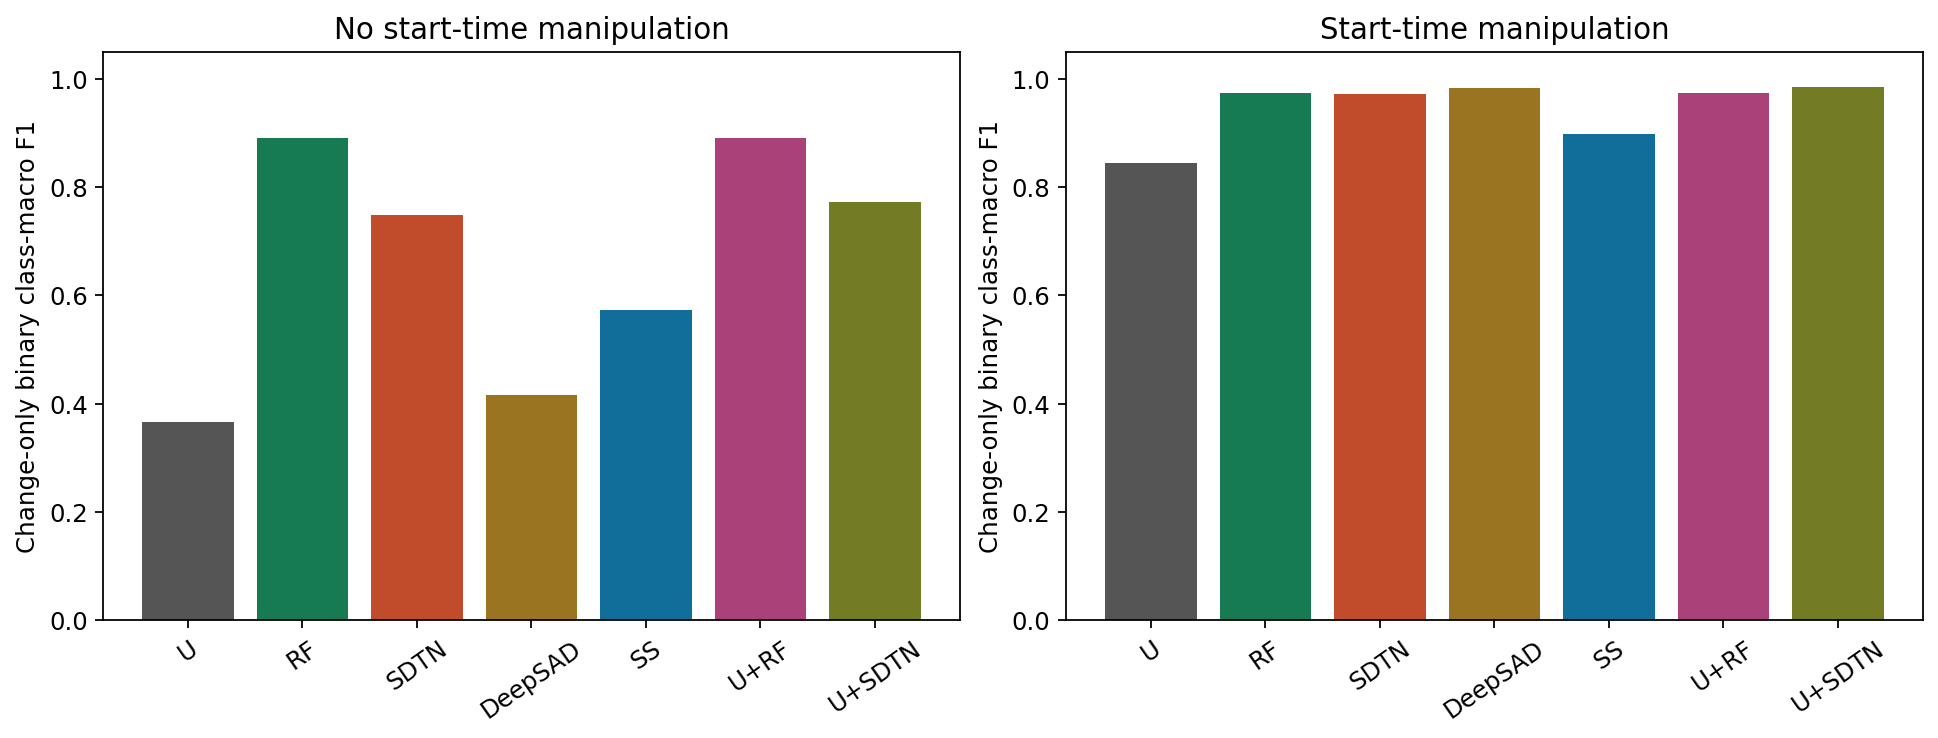

### known_type_learning_curves

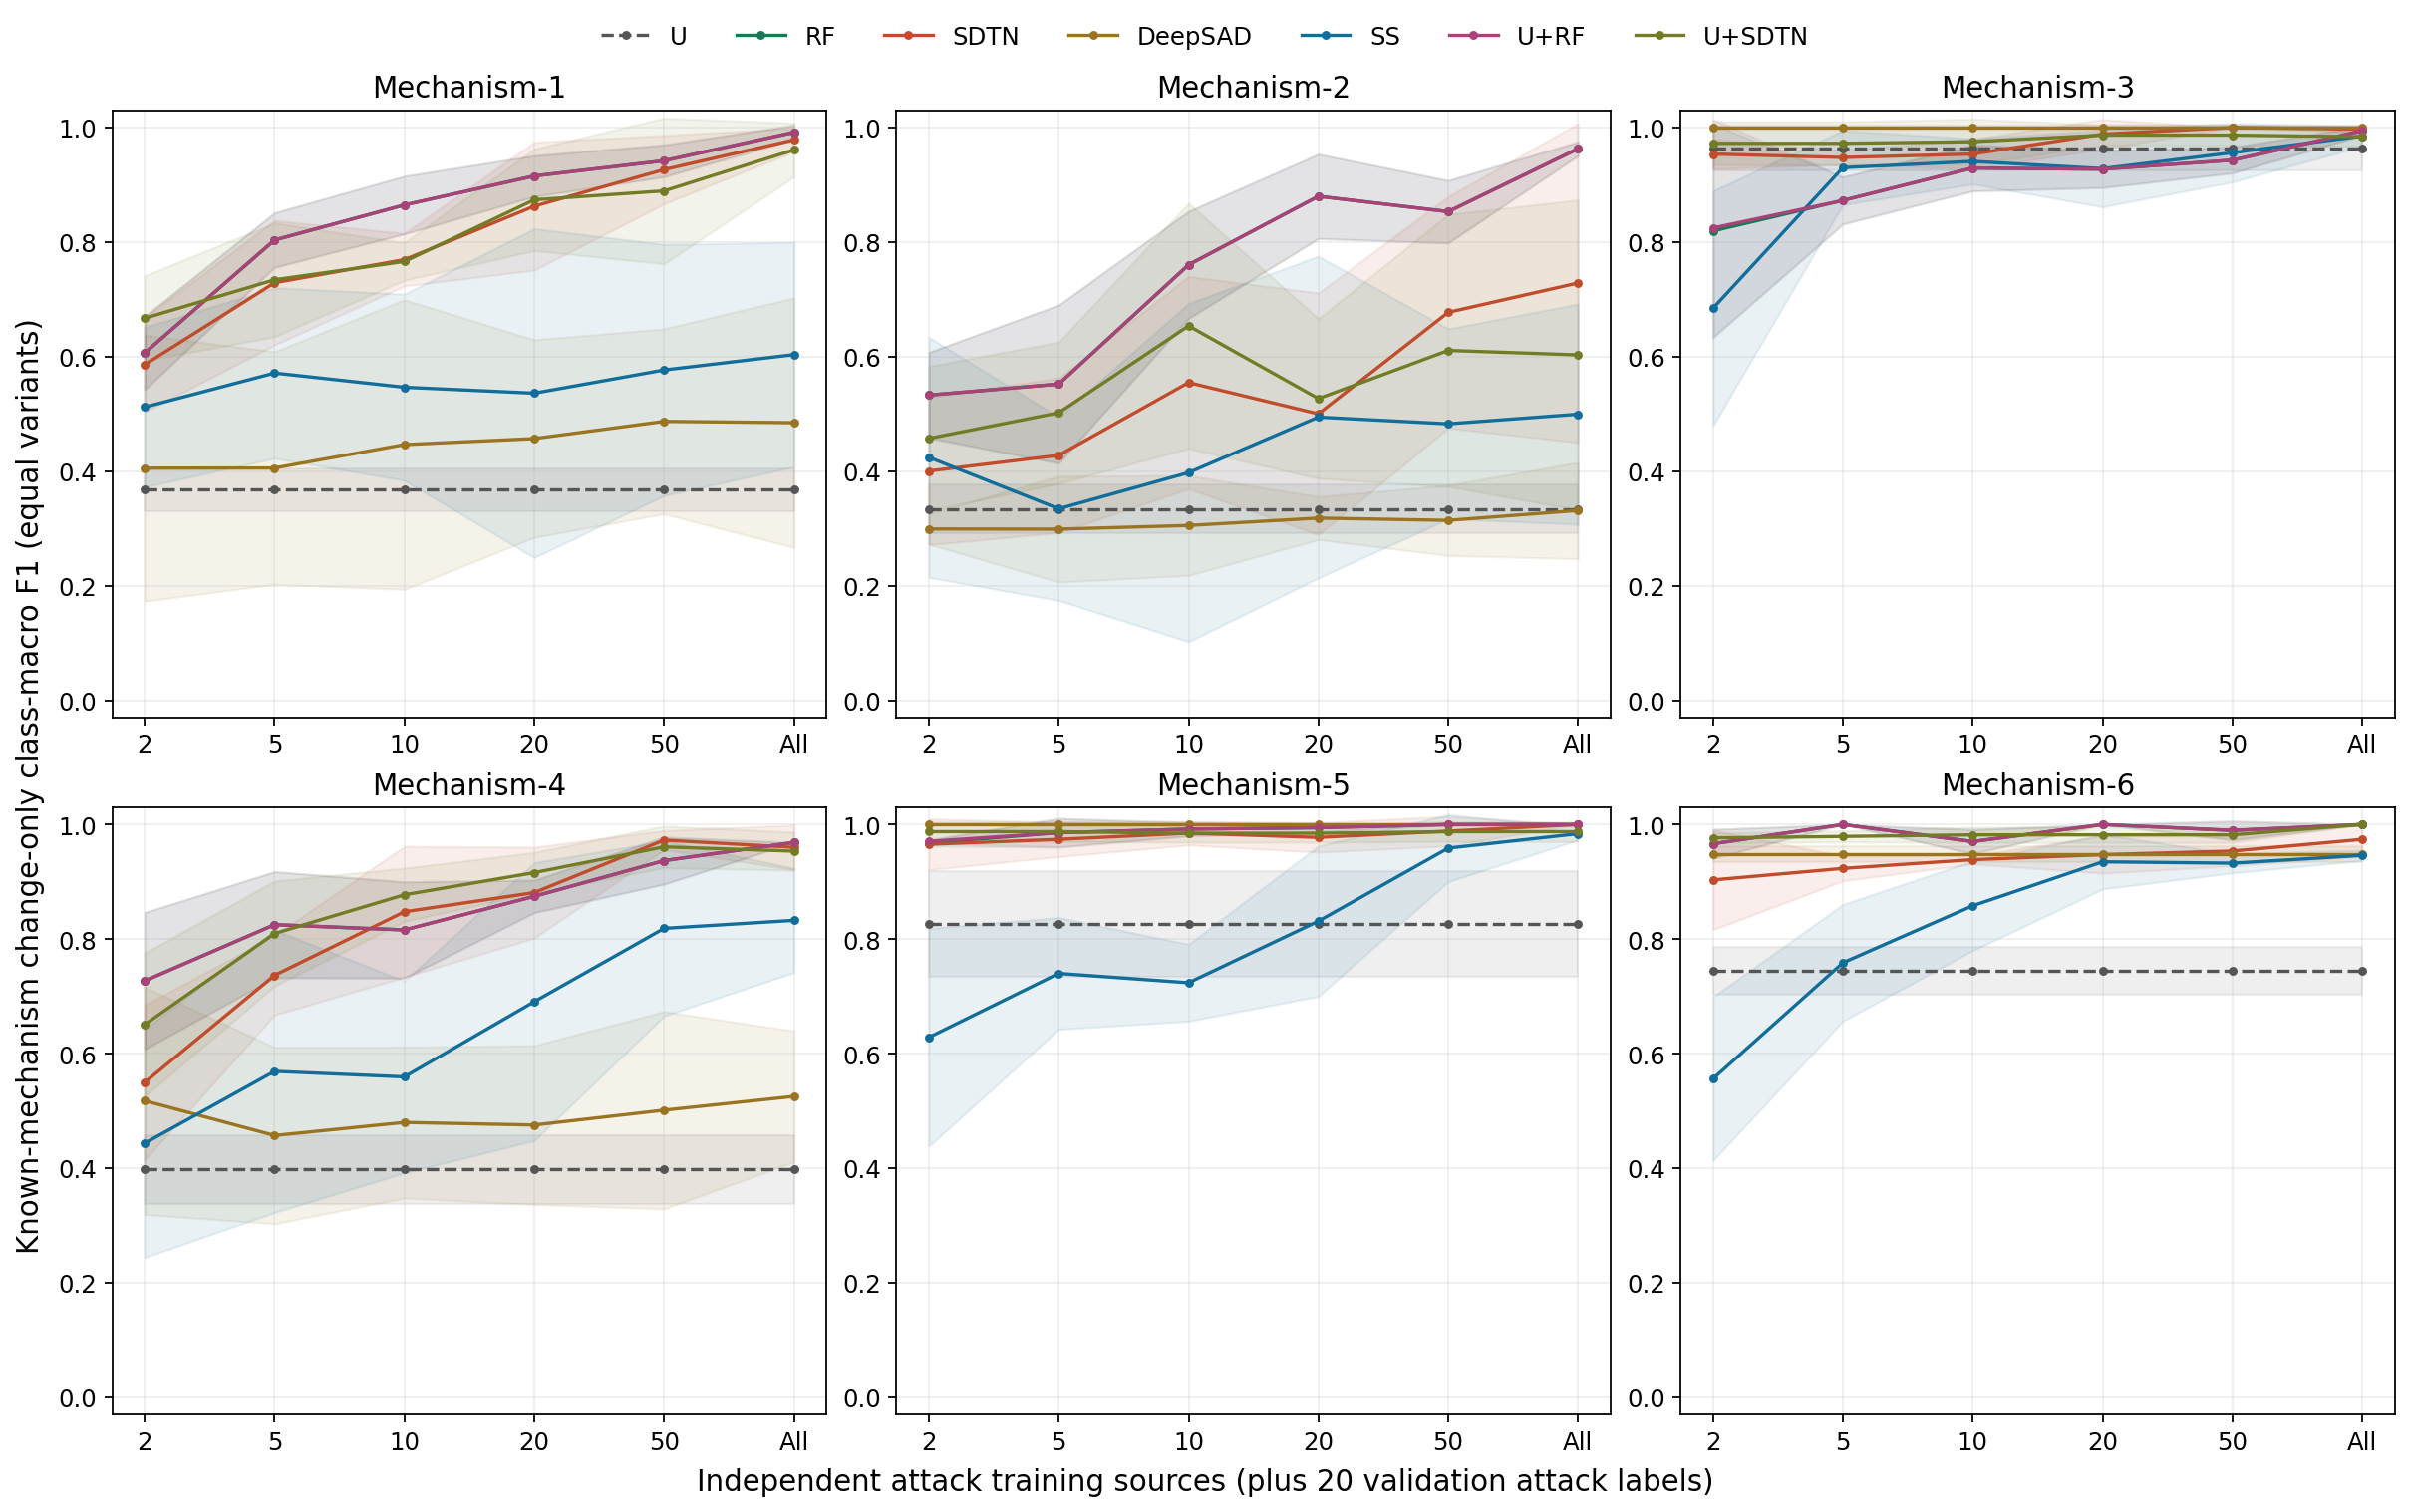

### six_by_twelve_variant_recall_n20

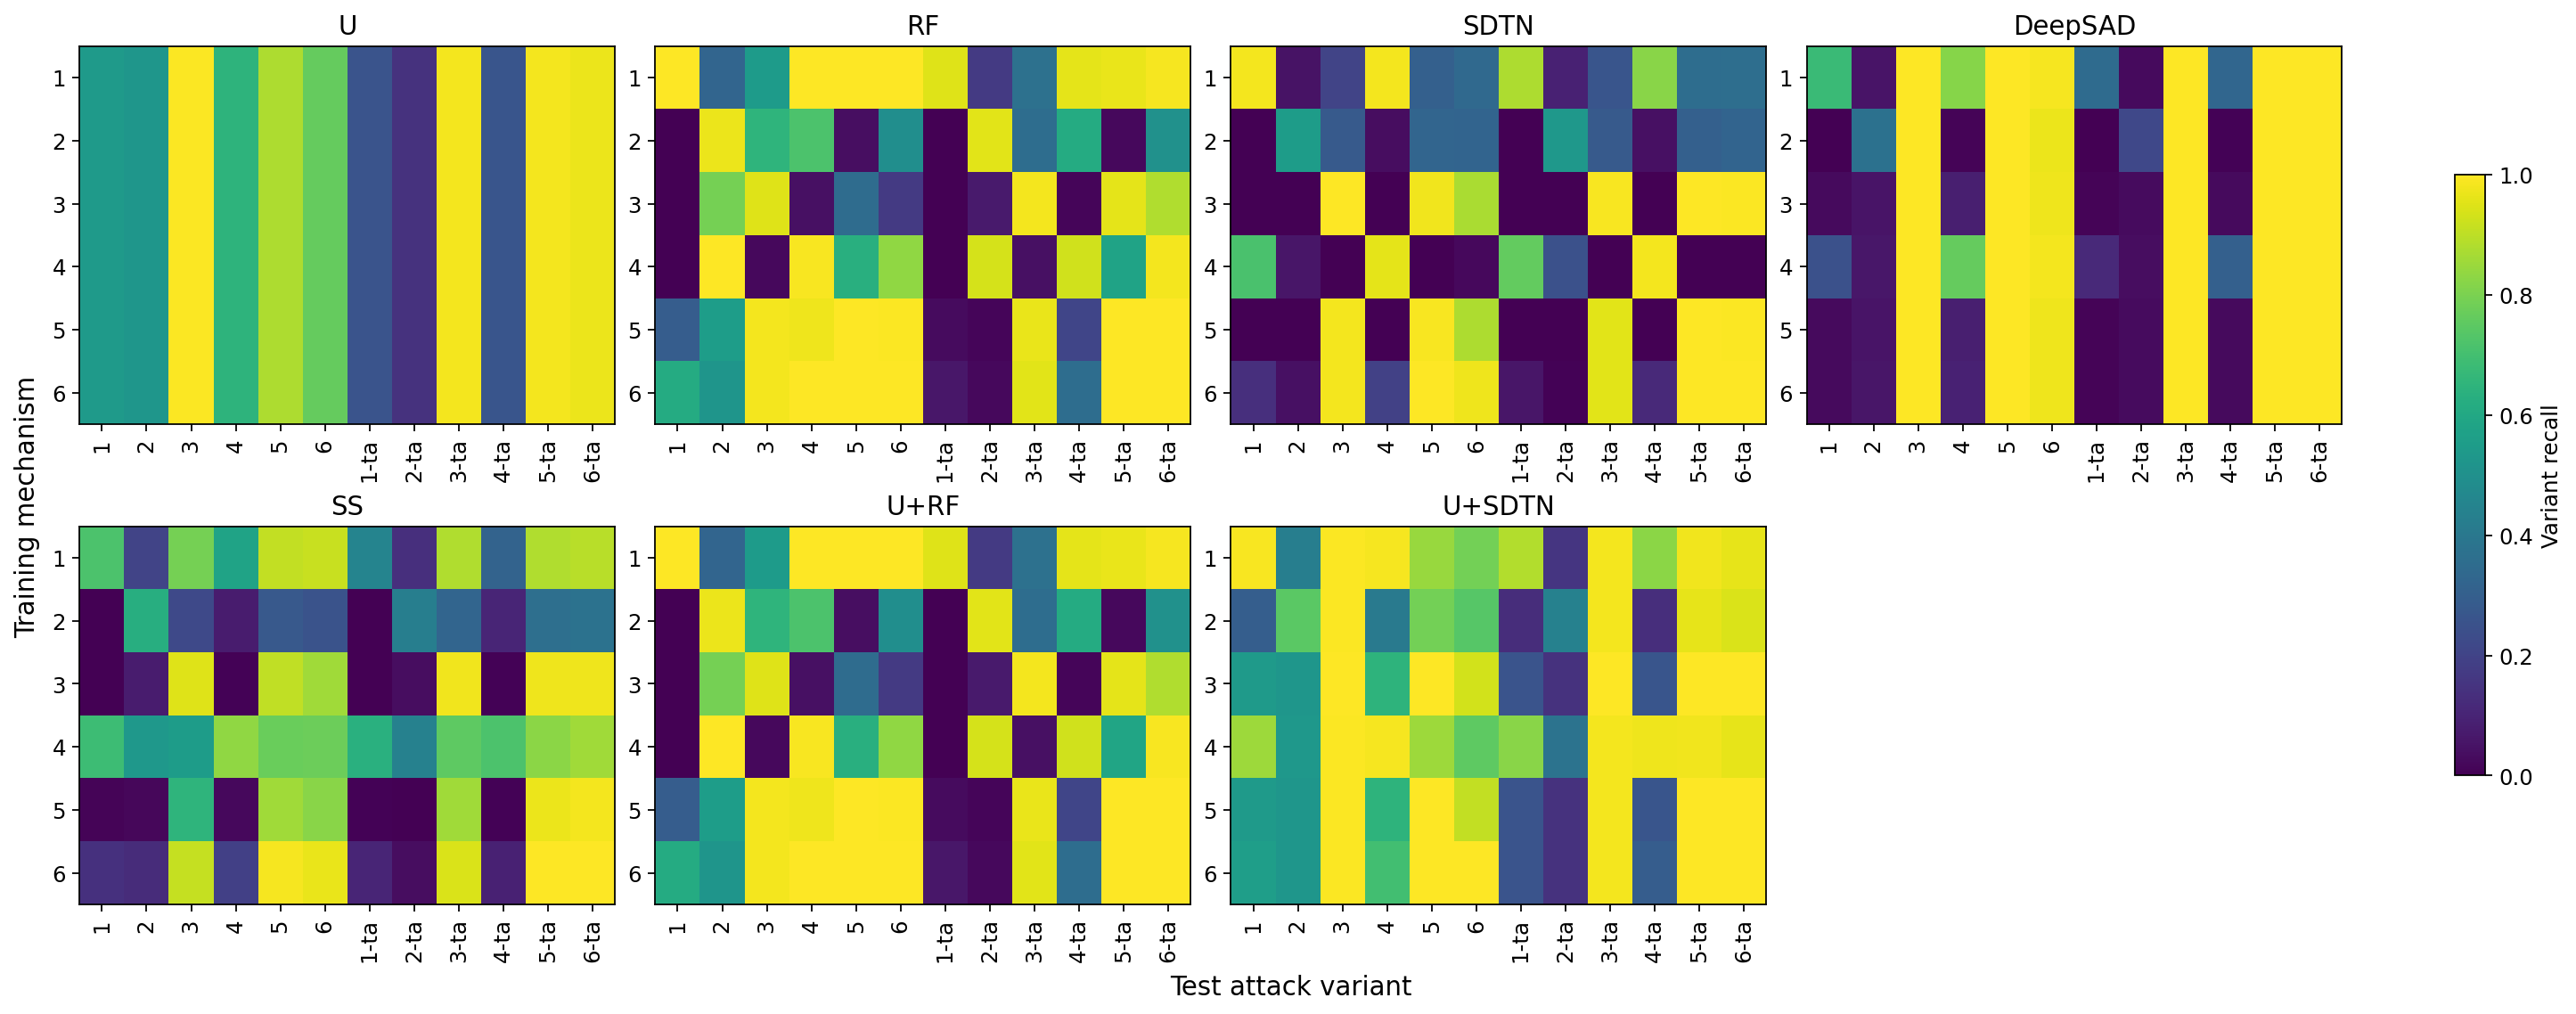

In [4]:
for path in sorted((ROOT/'figures').glob('*.png')):
 display(Markdown('### '+path.stem)); display(Image(filename=str(path)))

In [5]:
from verify_download import verify
audit=verify(ROOT)
display(audit)

{
  "status": "passed",
  "assertions": 653015,
  "development_base_fits": 4320,
  "recorded_fit_failures": 0,
  "frozen_test_cases": 1440,
  "setting_rows": 8640,
  "variant_rows": 17280,
  "protocol_signature": "3f64ffa0426fa292274d4bb935f8da5869afd5c356a8227043df545250ac19f0",
  "selection_signature": "5523199fcd923d21c7192e1abcc0383e858a17676613ab14a0bac55731abe304",
  "scope": "independent source/label/threshold/selection/count audit; not proof of real-world generalization"
}


{'status': 'passed',
 'assertions': 653015,
 'development_base_fits': 4320,
 'recorded_fit_failures': 0,
 'frozen_test_cases': 1440,
 'setting_rows': 8640,
 'variant_rows': 17280,
 'protocol_signature': '3f64ffa0426fa292274d4bb935f8da5869afd5c356a8227043df545250ac19f0',
 'selection_signature': '5523199fcd923d21c7192e1abcc0383e858a17676613ab14a0bac55731abe304',
 'scope': 'independent source/label/threshold/selection/count audit; not proof of real-world generalization'}